<a href="https://colab.research.google.com/github/roxanamore280-sketch/Pontia_SuperStore/blob/main/ANN_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Solo en google colab
# Cambia el entorno de ejecución a TPU

In [2]:
# Solo en google colab
# Instalar tensorflow_addons
#pip install tensorflow_addons
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 923.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 32.3 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
#import tensorflow_addons as tfa
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib as plt
import seaborn as sns
sns.set(style="darkgrid")

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


## Tensorflow

¿Cuál es valor de $w$ que minimiza el valor de la siguiente función siendo $x = [100, -5, 2]$?

$$x_0 + x_1w + x_2w^2$$

#### Solución
$w=5/4$

### Definición del modelo

In [5]:
# Coeficientes a optimizar
w = tf.Variable(0, name='w', dtype=tf.float32)
# Función a optimizar/minimizar
f = lambda: w**2. -20.*w + 100.

# Optimizador de tipo descenso de gradiente estocástico
optimizer = tf.optimizers.SGD(learning_rate=1.) #TODO

# Iteramos 20 veces el optimizador
for i in range(20):
    with tf.GradientTape() as tape:
      loss = f()
    grad = tape.gradient(loss, [w])
    optimizer.apply_gradients(zip(grad, [w]))
    print("iterations: ", i, ",\f: ", f().numpy(), ",\tw: ", w.numpy())

iterations:  0 ,:  100.0 ,	w:  20.0
iterations:  1 ,:  100.0 ,	w:  0.0
iterations:  2 ,:  100.0 ,	w:  20.0
iterations:  3 ,:  100.0 ,	w:  0.0
iterations:  4 ,:  100.0 ,	w:  20.0
iterations:  5 ,:  100.0 ,	w:  0.0
iterations:  6 ,:  100.0 ,	w:  20.0
iterations:  7 ,:  100.0 ,	w:  0.0
iterations:  8 ,:  100.0 ,	w:  20.0
iterations:  9 ,:  100.0 ,	w:  0.0
iterations:  10 ,:  100.0 ,	w:  20.0
iterations:  11 ,:  100.0 ,	w:  0.0
iterations:  12 ,:  100.0 ,	w:  20.0
iterations:  13 ,:  100.0 ,	w:  0.0
iterations:  14 ,:  100.0 ,	w:  20.0
iterations:  15 ,:  100.0 ,	w:  0.0
iterations:  16 ,:  100.0 ,	w:  20.0
iterations:  17 ,:  100.0 ,	w:  0.0
iterations:  18 ,:  100.0 ,	w:  20.0
iterations:  19 ,:  100.0 ,	w:  0.0


## Perceptrón simple: Compuertas AND, OR y XOR

In [7]:
# Entradas a la compuerta
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]], dtype=np.float32)

y_and = np.array([[0.],[0.],[0.],[1.]], dtype=np.float32)

y_or = np.array([[0.],[1.],[1.],[1.]], dtype=np.float32)

y_xor = np.array([[0.],[1.],[1.],[0.]], dtype=np.float32)

#### Primero intentemos obtener los pesos manualmente. Define los pesos y el bías como constantes.

In [8]:
#SOLUCION
# Definimos los pesos y bias
W = tf.constant([[0.],[0.]], name='W', dtype=tf.float32)
b = tf.constant(0., name='b', dtype=tf.float32)

# Perceptrón simple (con función de activación sigmoide)
y_ = tf.nn.sigmoid(tf.matmul(X, W, name='mat_mul') + b, name="logits")

# Resultado
print("Output", np.round(y_.numpy()).reshape(4,))

Output [0. 0. 0. 0.]


#### Probemos ahora optimizando con tensorflow

In [9]:
# SOLUCION

# Definimos los pesos, ahora son variables porque tenemos que optimizarlos
W = tf.Variable(tf.random.normal(shape = [2, 1], stddev=1./np.sqrt(2)), name='W', dtype=tf.float32)
b = tf.Variable(tf.zeros([1]), name='bias', dtype=tf.float32)

#Definimos las métricas
cost = tf.metrics.Mean(name='cost')
accuracy = tf.metrics.BinaryAccuracy(name='accuracy')

#Definimos el optimizador (SGD)
optimizer = tf.optimizers.SGD(learning_rate=1.)

@tf.function
def train_step(X, y):
    with tf.GradientTape() as tape:
        # Se registran las funciones a optimizar
        y_ = tf.nn.sigmoid(tf.matmul(X, W, name='matmul') + b, name="logits")
        # Usar binary_crossentropy
        loss = tf.losses.binary_crossentropy(y, y_)
    #Obtenemos los gradientes
    gradients = tape.gradient(loss, (W,b))
    #Optimizamos (1 paso)
    optimizer.apply_gradients(zip(gradients, (W,b)))

    #Calculamos las métricas
    cost(loss)
    accuracy(y, y_)

Probemos el funcionamiento de nuetro perceptron simple con las tres compuertas
#### AND

In [10]:
EPOCHS = 20

for epoch in range(EPOCHS):
    # Reset the metrics at the start of the next epoch
    #cost.reset_states()
    #accuracy.reset_states()

    train_step(X, y_and)

    template = 'Epoch {}, Cost: {}, Accuracy: {}'
    print(template.format(epoch+1,
                        cost.result(),
                        accuracy.result()*100))

y_ = tf.nn.sigmoid(tf.matmul(X, W, name='matmul') + b, name="sigmoid")
print("Output", np.round(y_.numpy()).reshape(4,))

Epoch 1, Cost: 0.763350248336792, Accuracy: 75.0
Epoch 2, Cost: 0.700031042098999, Accuracy: 75.0
Epoch 3, Cost: 0.6480357646942139, Accuracy: 75.0
Epoch 4, Cost: 0.6049164533615112, Accuracy: 75.0
Epoch 5, Cost: 0.5686642527580261, Accuracy: 75.0
Epoch 6, Cost: 0.5377445816993713, Accuracy: 79.16667175292969
Epoch 7, Cost: 0.511013925075531, Accuracy: 82.14286041259766
Epoch 8, Cost: 0.4876220226287842, Accuracy: 84.375
Epoch 9, Cost: 0.4669314920902252, Accuracy: 86.1111068725586
Epoch 10, Cost: 0.4484582543373108, Accuracy: 87.5
Epoch 11, Cost: 0.4318293333053589, Accuracy: 88.63636016845703
Epoch 12, Cost: 0.4167531430721283, Accuracy: 89.58332824707031
Epoch 13, Cost: 0.40299859642982483, Accuracy: 90.38461303710938
Epoch 14, Cost: 0.39038005471229553, Accuracy: 91.07142639160156
Epoch 15, Cost: 0.37874653935432434, Accuracy: 91.66667175292969
Epoch 16, Cost: 0.36797410249710083, Accuracy: 92.1875
Epoch 17, Cost: 0.35795968770980835, Accuracy: 92.64705657958984
Epoch 18, Cost: 0.3

#### OR
Ejecutar primero el bloque donde se definen los pesos para reinicializar los valores

In [11]:
EPOCHS = 20

for epoch in range(EPOCHS):
    # Reset the metrics at the start of the next epoch
    #cost.reset_states()
    #accuracy.reset_states()

    train_step(X, y_or)

    template = 'Epoch {}, Cost: {}, Accuracy: {}'
    print(template.format(epoch+1,
                        cost.result(),
                        accuracy.result()*100))

y_ = tf.nn.sigmoid(tf.matmul(X, W, name='matmul') + b, name="sigmoid")
print("Output", np.round(y_.numpy()).reshape(4,))

Epoch 1, Cost: 0.36129894852638245, Accuracy: 91.66667175292969
Epoch 2, Cost: 0.35099703073501587, Accuracy: 92.04545593261719
Epoch 3, Cost: 0.34007832407951355, Accuracy: 92.39130401611328
Epoch 4, Cost: 0.32959067821502686, Accuracy: 92.70832824707031
Epoch 5, Cost: 0.31971022486686707, Accuracy: 93.0
Epoch 6, Cost: 0.310444176197052, Accuracy: 93.26922607421875
Epoch 7, Cost: 0.3017562925815582, Accuracy: 93.51851654052734
Epoch 8, Cost: 0.29360026121139526, Accuracy: 93.75
Epoch 9, Cost: 0.28592991828918457, Accuracy: 93.96551513671875
Epoch 10, Cost: 0.27870258688926697, Accuracy: 94.16666412353516
Epoch 11, Cost: 0.27187973260879517, Accuracy: 94.3548355102539
Epoch 12, Cost: 0.2654268741607666, Accuracy: 94.53125
Epoch 13, Cost: 0.25931334495544434, Accuracy: 94.69696807861328
Epoch 14, Cost: 0.2535117566585541, Accuracy: 94.85294342041016
Epoch 15, Cost: 0.24799764156341553, Accuracy: 95.0
Epoch 16, Cost: 0.24274905025959015, Accuracy: 95.1388931274414
Epoch 17, Cost: 0.23774

#### XOR
Ejecutar primero el bloque donde se definen los pesos para reinicializar los valores

In [12]:
EPOCHS = 20

for epoch in range(EPOCHS):
    # Reset the metrics at the start of the next epoch
    #cost.reset_states()
    #accuracy.reset_states()

    train_step(X, y_xor)

    template = 'Epoch {}, Cost: {}, Accuracy: {}'
    print(template.format(epoch+1,
                        cost.result(),
                        accuracy.result()*100))

y_ = tf.nn.sigmoid(tf.matmul(X, W, name='matmul') + b, name="sigmoid")
print("Output", np.round(y_.numpy()).reshape(4,))

Epoch 1, Cost: 0.26985636353492737, Accuracy: 95.1219482421875
Epoch 2, Cost: 0.2985270321369171, Accuracy: 94.64286041259766
Epoch 3, Cost: 0.32004353404045105, Accuracy: 93.02326202392578
Epoch 4, Cost: 0.3387598395347595, Accuracy: 91.4772720336914
Epoch 5, Cost: 0.3551826477050781, Accuracy: 90.0
Epoch 6, Cost: 0.3695659935474396, Accuracy: 88.58695983886719
Epoch 7, Cost: 0.38215094804763794, Accuracy: 87.23404693603516
Epoch 8, Cost: 0.393170028924942, Accuracy: 85.9375
Epoch 9, Cost: 0.40284502506256104, Accuracy: 84.69387817382812
Epoch 10, Cost: 0.41138336062431335, Accuracy: 83.5
Epoch 11, Cost: 0.41897422075271606, Accuracy: 82.35294342041016
Epoch 12, Cost: 0.4257850646972656, Accuracy: 81.25
Epoch 13, Cost: 0.43195945024490356, Accuracy: 80.18868255615234
Epoch 14, Cost: 0.4376165568828583, Accuracy: 79.16667175292969
Epoch 15, Cost: 0.44285261631011963, Accuracy: 78.18182373046875
Epoch 16, Cost: 0.44774341583251953, Accuracy: 77.23213958740234
Epoch 17, Cost: 0.452347844

#### ¿Qué ha sucedido con la compuerta XOR?

## Perceptrón Multicapa: Compuerta XOR
Crear un perceptron multicapa con topología 2-2-1 (2 entradas, 2 ocultas y una salida)

In [15]:
# Pesos del perceptrón multicapa
Wh = #TODO
bh = #TODO

Wo = #TODO
bo = #TODO

#Definimos las métricas
cost = #TODO
accuracy = #TODO

#Definimos el optimizador (SGD)
optimizer = #TODO

@tf.function
def train_step(X, y):
    with tf.GradientTape() as tape:
        # Se registran las funciones a optimizar
        # Perceptrón multicapa
        #Capa oculta
        a_h = #TODO
        #Capa de salida
        y_ = #TODO
        # Usar binary_crossentropy
        loss = #TODO
    #Obtenemos los gradientes
    gradients = #TODO
    #Optimizamos (1 paso)
    optimizer.#TODO

    #Calculamos las métricas
    cost(#TODO
    accuracy(#TODO

SyntaxError: invalid syntax (696052016.py, line 2)

In [17]:
# SOLUCION

# Pesos del perceptrón multicapa
Wh = tf.Variable(tf.random.truncated_normal(shape = [2, 2], stddev=1./np.sqrt(2)), name='Wh', dtype=tf.float32)
bh = tf.Variable(tf.zeros([2]), name='bh', dtype=tf.float32)

Wo = tf.Variable(tf.random.truncated_normal(shape = [2, 1], stddev=1./np.sqrt(2)), name='Wo', dtype=tf.float32)
bo = tf.Variable(tf.zeros([1]), name='bo', dtype=tf.float32)

#Definimos las métricas
cost = tf.metrics.Mean(name='cost')
accuracy = tf.metrics.BinaryAccuracy(name='accuracy')

#Definimos el optimizador (SGD)
optimizer = tf.optimizers.SGD(learning_rate=.1)

@tf.function
def train_step(X, y):
    with tf.GradientTape() as tape:
        # Se registran las funciones a optimizar
        # Perceptrón multicapa
        # Capa oculta
        a_h = tf.nn.tanh(tf.matmul(X, Wh) + bh, name='a_h')
        # Capa de salida
        y_ = tf.nn.sigmoid(tf.matmul(a_h, Wo) + bo, name='y_')
        # Usar binary_crossentropy
        loss = tf.losses.binary_crossentropy(y, y_)
    #Obtenemos los gradientes
    gradients = tape.gradient(loss, (Wh,bh,Wo,bo))
    #Optimizamos (1 paso)
    optimizer.apply_gradients(zip(gradients, (Wh,bh,Wo,bo)))

    #Calculamos las métricas
    cost(loss)
    accuracy(y, y_)

Ejecuta varias veces junto al anterior, no encuentra siempre la solución

In [18]:
EPOCHS = 800

for epoch in range(EPOCHS):
    # Reset the metrics at the start of the next epoch
    #cost.reset_states()
    #accuracy.reset_states()

    train_step(X, y_xor)
    if epoch%50==0:
        template = 'Epoch {}, Cost: {}, Accuracy: {}'
        print(template.format(epoch+1,
                            cost.result(),
                            accuracy.result()*100))

y_ = tf.nn.sigmoid(tf.matmul(tf.nn.tanh(tf.matmul(X, Wh) + bh, name='a_h'), Wo) + bo, name='y_')
print("Output", np.round(y_.numpy()).reshape(4,))

Epoch 1, Cost: 0.6937041282653809, Accuracy: 75.0
Epoch 51, Cost: 0.682752788066864, Accuracy: 50.490196228027344
Epoch 101, Cost: 0.6560777425765991, Accuracy: 61.633663177490234
Epoch 151, Cost: 0.6055760383605957, Accuracy: 66.22516632080078
Epoch 201, Cost: 0.5202795267105103, Accuracy: 74.62686157226562
Epoch 251, Cost: 0.44077980518341064, Accuracy: 79.6812744140625
Epoch 301, Cost: 0.3797202408313751, Accuracy: 83.05648040771484
Epoch 351, Cost: 0.3329709470272064, Accuracy: 85.47008514404297
Epoch 401, Cost: 0.29637789726257324, Accuracy: 87.28179168701172
Epoch 451, Cost: 0.26705658435821533, Accuracy: 88.6917953491211
Epoch 501, Cost: 0.24306875467300415, Accuracy: 89.82035827636719
Epoch 551, Cost: 0.22309203445911407, Accuracy: 90.74410247802734
Epoch 601, Cost: 0.20620161294937134, Accuracy: 91.5141372680664
Epoch 651, Cost: 0.19173412024974823, Accuracy: 92.16590118408203
Epoch 701, Cost: 0.17920243740081787, Accuracy: 92.72467803955078
Epoch 751, Cost: 0.1682414710521698

## Problema regresión: Diabetes

In [19]:
import io
import requests

# https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html
# age, sex, body mass index, average blood pressure, and six blood serum measurements
url="https://www4.stat.ncsu.edu/~boos/var.select/diabetes.tab.txt"
c=requests.get(url).content
diabetes=pd.read_csv(io.StringIO(c.decode('utf-8')), sep='\t')

In [ ]:
diabetes.head()

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,Y
0,59,2,32.1,101.0,157,93.2,38.0,4.0,4.8598,87,151
1,48,1,21.6,87.0,183,103.2,70.0,3.0,3.8918,69,75
2,72,2,30.5,93.0,156,93.6,41.0,4.0,4.6728,85,141
3,24,1,25.3,84.0,198,131.4,40.0,5.0,4.8903,89,206
4,50,1,23.0,101.0,192,125.4,52.0,4.0,4.2905,80,135


In [20]:
from sklearn.model_selection import train_test_split

diabetes['SEX'] -= 1
X_train, X_test, y_train, y_test = train_test_split(diabetes.drop('Y', axis=1).values,
                                                    #Aniadimos una dimension para que sea un vector columna
                                                    diabetes['Y'].values[..., np.newaxis],
                                                    test_size=0.2, random_state=0)

In [21]:
from sklearn.preprocessing import StandardScaler

class StandardScalerSelection(StandardScaler):
    '''Solo funciona con pandas '''

    def __init__(self, copy=True, with_mean=True, with_std=True, skip_cols=None):
        self.skip_cols = np.array(skip_cols).flatten().tolist()
        super().__init__(copy=copy, with_mean=with_mean, with_std=with_std)

    def fit(self, X, y=None):
        return super().fit(np.delete(X, self.skip_cols, axis=1))

    def transform(self, X):
        X_scl = super().transform(np.delete(X, self.skip_cols, axis=1))
        # Restar uno por cada indice anterior para que asi se inserte en su posición
        idx = np.array(skip_cols)-np.arange(len(skip_cols))
        return np.insert(X_scl, idx, X[:,self.skip_cols], axis=1)

In [22]:
skip_cols = sorted([diabetes.columns.get_loc(c) for c in ['SEX'] if c in diabetes])
scaler = StandardScalerSelection(skip_cols=skip_cols)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#Si la salida es una sola neurona, tienes que pasarle la salida como un vector columna
y_train = y_train.astype(np.float64)
y_test = y_test.astype(np.float64)

### TensorFlow

In [23]:
#TODO
# Pesos del perceptrón multicapa
Wh1 = #TODO
bh1 = #TODO

Wh2 = #TODO
bh2 = #TODO

Wo = #TODO
bo = #TODO

#Definimos las funciones de coste
train_cost = #TODO
train_r2 = #TODO
test_cost = #TODO
test_r2 = #TODO


#Definimos el optimizador (Adam)
optimizer = #TODO

@tf.function
def train_step(X, y):
    #TODO

# Función para obtener la precision y coste en test
@tf.function
def test(X, y):
    # Perceptrón multicapa
    #TODO
    # Funcion de perdida
    #TODO
    #Calculamos las métricas
    #TODO

SyntaxError: invalid syntax (182511695.py, line 3)

In [24]:
# SOLUCION

h1_size=64
h2_size=32

# Pesos del perceptrón multicapa
Wh1 = tf.Variable(tf.random.truncated_normal(shape = [X_train.shape[1], h1_size], stddev=1./np.sqrt(X_train.shape[1]), dtype=tf.float64), name='Wh1')
bh1 = tf.Variable(tf.zeros([h1_size], dtype=tf.float64), name='bh1')

Wh2 = tf.Variable(tf.random.truncated_normal(shape = [h1_size, h2_size], stddev=1./np.sqrt(h1_size), dtype=tf.float64), name='Wh2')
bh2 = tf.Variable(tf.zeros([h2_size], dtype=tf.float64), name='bh2')

Wo = tf.Variable(tf.random.truncated_normal(shape = [h2_size, 1], stddev=1./np.sqrt(h2_size), dtype=tf.float64), name='Wo')
bo = tf.Variable(tf.zeros([1], dtype=tf.float64), name='bo')

#Definimos las funciones de coste
train_cost = tf.metrics.Mean(name='train_cost')
# y_shape=(1,) expecifica que la salida es de tipo vector columna
train_r2 = tf.keras.metrics.R2Score(name='train_r2', dtype=tf.float64)
test_cost = tf.metrics.Mean(name='test_cost')
test_r2 = tf.keras.metrics.R2Score(name='test_r2', dtype=tf.float64)



#Definimos el optimizador (Adam)
optimizer = tf.optimizers.Adam(learning_rate=1.)

@tf.function
def train_step(X, y):
    with tf.GradientTape() as tape:
        # Se registran las funciones a optimizar
        # Perceptrón multicapa
        # Capas ocultas
        a_h1 = tf.nn.tanh(tf.matmul(X, Wh1) + bh1, name='a_h1')
        a_h2 = tf.nn.tanh(tf.matmul(a_h1, Wh2) + bh2, name='a_h2')
        # Capa de salida para problema de regresión podemos dejarla sin función de activación
        y_ = tf.matmul(a_h2, Wo, name='y_b') + bo
        # Usar mean_squared_error
        loss = tf.compat.v1.losses.mean_squared_error(y, y_)
    #Obtenemos los gradientes
    gradients = tape.gradient(loss, (Wh1, bh1, Wh2, bh2, Wo, bo))
    #Optimizamos (1 paso)
    optimizer.apply_gradients(zip(gradients, (Wh1, bh1, Wh2, bh2, Wo, bo)))
    #Calculamos las métricas
    train_cost(loss)
    train_r2(y,y_)

# Función para obtener la precision y coste en test
@tf.function
def test(X, y):
    # Perceptrón multicapa
    # Capas ocultas
    a_h1 = tf.nn.tanh(tf.matmul(X, Wh1) + bh1, name='a_h1')
    a_h2 = tf.nn.tanh(tf.matmul(a_h1, Wh2) + bh2, name='a_h2')
    # Capa de salida
    y_ = tf.matmul(a_h2, Wo, name='y_b') + bo
    # Usar binary_crossentropy
    loss = tf.compat.v1.losses.mean_squared_error(y, y_)
    #Calculamos las métricas
    test_cost(loss)
    #Si no se lo pasas como un vector, tfa.metrics.RSquare falla
    test_r2(y,y_)

In [25]:
EPOCHS = 100

for epoch in range(EPOCHS):
    # Reset the metrics at the start of the next epoch
    #train_cost.reset_states()
    #train_r2.reset_states()
    #test_cost.reset_states()
    #test_r2.reset_states()

    train_step(X_train, y_train)
    test(X_test, y_test)
    if epoch%10==0:
        template = 'Epoch {:}, Train cost: {:.4f}, Train R2: {:.4f}, Test cost: {:.4f}, Test R2: {:.4f}'
        print(template.format(epoch+1,
                            train_cost.result(),
                            train_r2.result(),
                            train_cost.result(),
                            test_r2.result()))

Epoch 1, Train cost: 29078.5215, Train R2: -3.7431, Test cost: 29078.5215, Test R2: -4.2798
Epoch 11, Train cost: 17666.0273, Train R2: -1.8816, Test cost: 17666.0273, Test R2: -1.9207
Epoch 21, Train cost: 11412.0801, Train R2: -0.8615, Test cost: 11412.0801, Test R2: -0.9365
Epoch 31, Train cost: 8813.3770, Train R2: -0.4376, Test cost: 8813.3770, Test R2: -0.5514
Epoch 41, Train cost: 7397.4990, Train R2: -0.2066, Test cost: 7397.4990, Test R2: -0.3672
Epoch 51, Train cost: 6491.5054, Train R2: -0.0589, Test cost: 6491.5054, Test R2: -0.2523
Epoch 61, Train cost: 5861.0195, Train R2: 0.0440, Test cost: 5861.0195, Test R2: -0.1831
Epoch 71, Train cost: 5401.2783, Train R2: 0.1190, Test cost: 5401.2783, Test R2: -0.1283
Epoch 81, Train cost: 5049.0737, Train R2: 0.1764, Test cost: 5049.0737, Test R2: -0.0967
Epoch 91, Train cost: 4769.8887, Train R2: 0.2220, Test cost: 4769.8887, Test R2: -0.0696


## Keras

In [26]:
#Modelo
model = keras.Sequential([
    #TODO
  ])

model.compile(#TODO

                )

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [27]:
# SOLUCION #
#Modelo
model = keras.Sequential([
    layers.Dense(64, activation=tf.nn.tanh, input_shape=[X_train.shape[1]], name='h1'),
    layers.Dense(32, activation=tf.nn.tanh, name='h2'),
    layers.Dense(1, name='o')
  ])

model.compile(loss='mean_squared_error',
              optimizer=tf.keras.optimizers.Adam(0.1),
              metrics=['mean_absolute_error', 'mean_squared_error'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ h1 (Dense)                      │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ h2 (Dense)                      │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ o (Dense)                       │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Entrenar el modelo
history = model.fit(#TODO

_IncompleteInputError: incomplete input (4277855516.py, line 2)

In [31]:
# SOLUCION #
# Entrenar el modelo
history = model.fit(X_train, y_train, epochs=100, validation_split = 0.2, verbose=1)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 24992.2500 - mean_absolute_error: 138.3666 - mean_squared_error: 24992.2500 - val_loss: 22687.0977 - val_mean_absolute_error: 124.6087 - val_mean_squared_error: 22687.0977
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 17375.6211 - mean_absolute_error: 107.4974 - mean_squared_error: 17375.6211 - val_loss: 16090.4053 - val_mean_absolute_error: 97.5265 - val_mean_squared_error: 16090.4053
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11932.6016 - mean_absolute_error: 84.1640 - mean_squared_error: 11932.6016 - val_loss: 11604.5264 - val_mean_absolute_error: 80.8453 - val_mean_squared_error: 11604.5264
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8672.9990 - mean_absolute_error: 72.0854 - mean_squared_error: 8672.9990 - val_loss: 8928.7451 - val_mean_absolute_error: 73.1529 - val_mean_squared_error: 8928.7451
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6754.3076 - mean_absolute_error: 66

In [ ]:
# Obtener la precisión del modelo
# TODO

In [32]:
#SOLUCION
# Obtener la precisión del modelo
model.evaluate(X_test, y_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5237.0146 - mean_absolute_error: 60.0311 - mean_squared_error: 5237.0146 


[5237.0146484375, 60.03111267089844, 5237.0146484375]

Mean Absolute Error Train: 67.26
Mean Absolute Error Test: 60.03
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
R2 Train: -0.00
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
R2 Test: -0.02


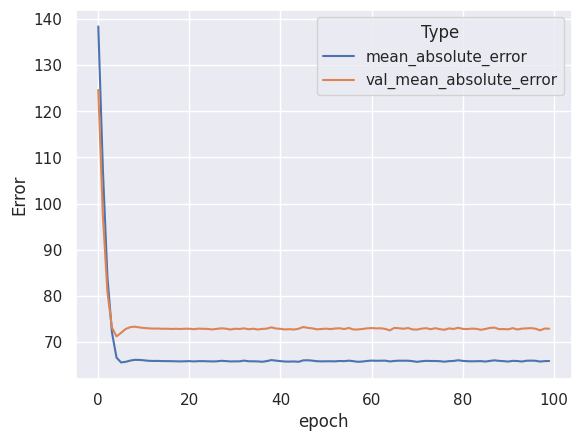

In [33]:
from sklearn.metrics import r2_score

hist = pd.DataFrame(history.history)
# Incluye la epoca para cada error
hist['epoch'] = history.epoch

# Colpasa los errores 'mean_absolute_error','val_mean_absolute_error' en una sola columna para sns
df = hist.melt(id_vars='epoch', var_name='Type', value_name='Error',
               value_vars=['mean_absolute_error','val_mean_absolute_error'])
# Plot the responses for different events and regions
_ = sns.lineplot(x='epoch', y='Error', hue='Type', data=df)


print("Mean Absolute Error Train: %.2f" % model.evaluate(X_train, y_train, verbose=0)[1])
print("Mean Absolute Error Test: %.2f" % model.evaluate(X_test, y_test, verbose=0)[1])
print("R2 Train: %.2f" % r2_score(y_train, model.predict(X_train)))
print("R2 Test: %.2f" % r2_score(y_test, model.predict(X_test)))

### Problema de clasificación: Breast Cancer

In [34]:
import io
import requests

# https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic)
url='https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data'
c=requests.get(url).content
cancer=pd.read_csv(io.StringIO(c.decode('utf-8')), header=None, index_col=0)

In [35]:
cancer.head()

,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
0,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [36]:
from sklearn.model_selection import train_test_split

cancer[1] = list(map(float, cancer[1].values=='M'))
X_train, X_test, y_train, y_test = train_test_split(cancer.drop(1, axis=1).values,
                                                    #Aniadimos una dimension para que sea un vector columna
                                                    cancer[1].values[..., np.newaxis],
                                                    test_size=0.2, random_state=0)


In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### TensorFlow
Utilizar en este caso la métrica `AUC`

Para la función de perdida, utilizar `binary_crossentropy` al ser un problema binario

## Tercera entrega:
### Arquitectura de la red para problema de calsificacion binaria:

Desarrollar el ejercicio usando Tensorflow.

*   Capa 1: num dimensiones x 64 neuronas
*   Capa salida: num dimensiones x ¿num neuronas clasificación binaria?


In [40]:
#TODO
# Pesos del perceptrón multicapa
#TODO

#Definimos las métricas
train_cost = tf.keras.metrics.Mean(name="train_cost")
train_auc = tf.keras.metrics.AUC(name="train_auc")
test_cost = tf.keras.metrics.Mean(name="test_cost")
test_auc = tf.keras.metrics.AUC(name="test_auc")


#TODO...


In [44]:
EPOCHS = 100

for epoch in range(EPOCHS):
   num_dimensiones = X_train.shape[1]   # aquí vale 30

Wh1 = tf.Variable(tf.random.normal([num_dimensiones, 64], stddev=0.1), name="Wh1")
bh1 = tf.Variable(tf.zeros([64]), name="bh1")

    train_step(X_train, y_train)
    test(X_test, y_test)
    if epoch%10==0:
        template = 'Epoch {:}, Train Cost: {:.4f}, Train AUC: {:.2f}, Test Cost: {:.4f}, Test AUC: {:.2f}'
        print(template.format(epoch+1,
                            train_cost.result(),
                            train_auc.result()*100,
                            test_cost.result(),
                            test_auc.result()*100))

IndentationError: unexpected indent (1128441486.py, line 9)

### Keras

In [ ]:
#TODO

In [45]:
#SOLUCION
#Modelo
model = keras.Sequential([
    layers.Dense(64, activation=tf.nn.relu, input_shape=[X_train.shape[1]], name='h1'),
    layers.Dense(32, activation=tf.nn.relu, name='h2'),
    layers.Dense(1, activation=tf.nn.sigmoid, name='o')
  ])

model.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.SGD(0.01),
              metrics=['binary_accuracy'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ h1 (Dense)                      │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ h2 (Dense)                      │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ o (Dense)                       │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
#SOLUCION
history = model.fit(X_train, y_train, epochs=100, validation_split = 0.2, verbose=0)

Accuracy Train: 0.98
Accuracy Test: 0.96


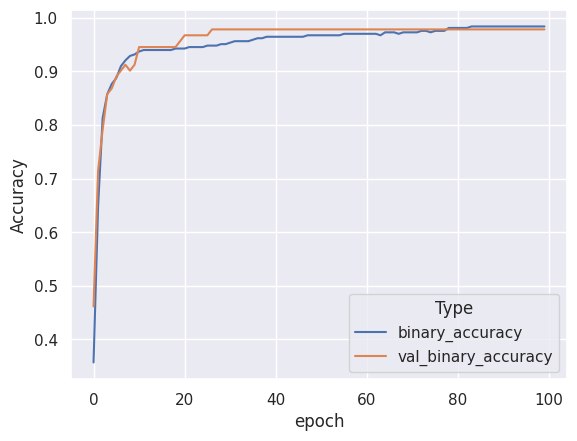

In [47]:
hist = pd.DataFrame(history.history)
# Incluye la epoca para cada error
hist['epoch'] = history.epoch

# Colpasa los errores 'mean_absolute_error','val_mean_absolute_error' en una sola columna para sns
df = hist.melt(id_vars='epoch', var_name='Type', value_name='Accuracy',
               value_vars=['binary_accuracy','val_binary_accuracy'])
# Plot the responses for different events and regions
_ = sns.lineplot(x='epoch', y='Accuracy', hue='Type', data=df)

print("Accuracy Train: %.2f" % model.evaluate(X_train, y_train, verbose=0)[1])
print("Accuracy Test: %.2f" % model.evaluate(X_test, y_test, verbose=0)[1])

## Problema de clasificación multiclase: MNIST

In [48]:
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [49]:
# Min max scaler a mano
X_train = train_images / 255.0
X_test = test_images / 255.0

In [50]:
# OneHotEncoding para AUC
from sklearn.preprocessing import LabelBinarizer

le = LabelBinarizer().fit(train_labels)
y_train_label = le.transform(train_labels)
y_test_label = le.transform(test_labels)

In [51]:
y_train = train_labels[..., np.newaxis]
y_test = test_labels[..., np.newaxis]

### Tensorflow

`sparse_categorical_crossentropy` funciona mejor en problemas donde las clases son mutuamente excluyentes, es decir, solo hay una clase positiva en cada tupla. `categorical_crossentropy` permite trabajar con problemas donde más de una clase puede ser positiva.

In [52]:
#TODO

In [53]:
# SOLUCION

# Pesos del perceptrón multicapa
Wh = tf.Variable(tf.random.truncated_normal(shape = [784, 64], stddev=1./np.sqrt(784), dtype=tf.float64), name='Wh')
bh = tf.Variable(tf.zeros([64], dtype=tf.float64), name='bh')

Wo = tf.Variable(tf.random.truncated_normal(shape = [64, 10], stddev=1./np.sqrt(64), dtype=tf.float64), name='Wo')
bo = tf.Variable(tf.zeros([10], dtype=tf.float64), name='bo')

#Definimos las métricas
train_cost = tf.metrics.Mean(name='cost')
train_auc = tf.metrics.AUC(name='accuracy')
test_cost = tf.metrics.Mean(name='cost')
test_auc = tf.metrics.AUC(name='accuracy')

#Definimos el optimizador (Adam)
optimizer = tf.optimizers.Adam(learning_rate=1.)

@tf.function
def train_step(X, y, y_label):

    with tf.GradientTape() as tape:
        # Se registran las funciones a optimizar
        # Perceptrón multicapa
        # Usar una capa flatten para pasar la matriz de entradas en una sola diensión
        X = tf.keras.layers.Flatten(dtype='float64')(X)
        # Capa oculta
        a_h = tf.nn.tanh(tf.matmul(X, Wh) + bh, name='a_h')
        # Capa de salida
        y_ = tf.nn.softmax(tf.matmul(a_h, Wo) + bo, name='y_')
        # Usar sparse_categorical_crossentropy para utilizar las etiquetas como enteros
        loss = tf.losses.sparse_categorical_crossentropy(y, y_)
        # Usar categorical_crossentropy para utilizar las etiquetas en formato OneHotEncoding
        #loss = tf.losses.categorical_crossentropy(y_label, y_)
    #Obtenemos los gradientes
    gradients = tape.gradient(loss, (Wh,bh,Wo,bo))
    #Optimizamos (1 paso)
    optimizer.apply_gradients(zip(gradients, (Wh,bh,Wo,bo)))
    #Calculamos las métricas
    train_cost(loss)
    train_auc(y_label, y_)

# Función para obtener la precision y coste en test
@tf.function
def test(X, y, y_label):
    # Usar flatten para pasar la matriz de entradas en una sola diensión
    X = tf.keras.layers.Flatten(dtype='float64')(X)
    # Perceptrón multicapa
    # Capa oculta
    a_h = tf.nn.tanh(tf.matmul(X, Wh) + bh, name='a_h')
    # Capa de salida
    y_ = tf.nn.sigmoid(tf.matmul(a_h, Wo) + bo, name='y_')
    # Usar sparse_categorical_crossentropy para utilizar las etiquetas como enteros
    loss = tf.losses.sparse_categorical_crossentropy(y, y_)
    # Usar categorical_crossentropy para utilizar las etiquetas en formato OneHotEncoding
    #loss = tf.losses.categorical_crossentropy(y_label, y_)
    #Calculamos las métricas
    test_cost(loss)
    test_auc(y_label, y_)

In [54]:
EPOCHS = 10

for epoch in range(EPOCHS):
    # Reset the metrics at the start of the next epoch
    #train_cost.reset_states()
    #train_auc.reset_states()
    #test_cost.reset_states()
    #test_auc.reset_states()

    train_step(X_train, y_train, y_train_label)
    test(X_test, y_test, y_test_label)
    if epoch%1==0:
        template = 'Epoch {:}, Train Cost: {:.4f}, Train AUC: {:.2f}, Test Cost: {:.4f}, Test AUC: {:.2f}'
        print(template.format(epoch+1,
                            train_cost.result(),
                            train_auc.result()*100,
                            test_cost.result(),
                            test_auc.result()*100))

Epoch 1, Train Cost: 2.3288, Train AUC: 49.47, Test Cost: 5.2798, Test AUC: 52.36
Epoch 2, Train Cost: 8.2262, Train AUC: 50.71, Test Cost: 5.6460, Test AUC: 53.25
Epoch 3, Train Cost: 12.8104, Train AUC: 56.94, Test Cost: 5.0699, Test AUC: 56.21
Epoch 4, Train Cost: 14.4149, Train AUC: 58.89, Test Cost: 4.3329, Test AUC: 60.42
Epoch 5, Train Cost: 14.5868, Train AUC: 61.93, Test Cost: 3.9914, Test AUC: 62.65
Epoch 6, Train Cost: 13.8677, Train AUC: 65.07, Test Cost: 3.8014, Test AUC: 64.28
Epoch 7, Train Cost: 14.2266, Train AUC: 66.37, Test Cost: 3.5992, Test AUC: 65.72
Epoch 8, Train Cost: 14.0049, Train AUC: 67.73, Test Cost: 3.3976, Test AUC: 66.98
Epoch 9, Train Cost: 13.4488, Train AUC: 68.96, Test Cost: 3.2280, Test AUC: 68.02
Epoch 10, Train Cost: 12.6553, Train AUC: 70.76, Test Cost: 3.0908, Test AUC: 68.92


### Keras
Probar a crear el modelo con y sin dropout y batch normalization para comparar los resultados de validación

In [55]:
#TODO

In [57]:
#SOLUCION
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(128, activation=tf.nn.relu),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(128, activation=tf.nn.relu),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(10, activation=tf.nn.softmax)
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,306 (466.04 KB)

 Trainable params: 118,794 (464.04 KB)

 Non-trainable params: 512 (2.00 KB)

In [58]:
#SOLUCION
model.compile(optimizer=tf.keras.optimizers.Adam(0.01),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=5, validation_split = 0.2)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8859 - loss: 0.3677 - val_accuracy: 0.9481 - val_loss: 0.1606
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9220 - loss: 0.2522 - val_accuracy: 0.9463 - val_loss: 0.1728
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9329 - loss: 0.2139 - val_accuracy: 0.9644 - val_loss: 0.1160
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9390 - loss: 0.1952 - val_accuracy: 0.9656 - val_loss: 0.1097
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9420 - loss: 0.1836 - val_accuracy: 0.9707 - val_loss: 0.0933


Accuracy Train: 0.98
Accuracy Test: 0.97


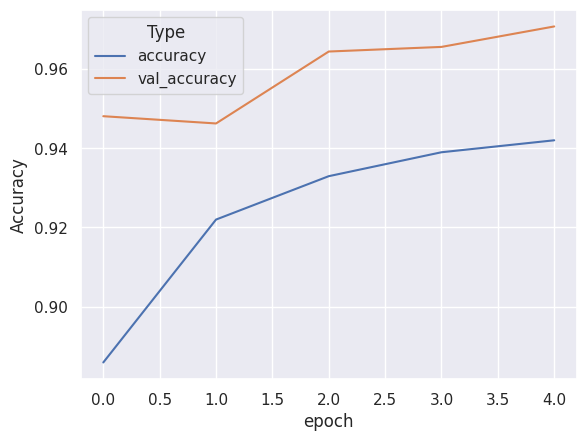

In [59]:
hist = pd.DataFrame(history.history)
# Incluye la epoca para cada error
hist['epoch'] = history.epoch

# Colpasa los errores 'mean_absolute_error','val_mean_absolute_error' en una sola columna para sns
df = hist.melt(id_vars='epoch', var_name='Type', value_name='Accuracy',
               value_vars=['accuracy','val_accuracy'])
# Plot the responses for different events and regions
_ = sns.lineplot(x='epoch', y='Accuracy', hue='Type', data=df)

print("Accuracy Train: %.2f" % model.evaluate(X_train, y_train, verbose=0)[1])
print("Accuracy Test: %.2f" % model.evaluate(X_test, y_test, verbose=0)[1])

In [60]:
#SOLUCION
model.evaluate(test_images, test_labels, verbose=0)

[20.209962844848633, 0.9383999705314636]